# 01 — E-commerce EDA

## Reproducibility and setup
The first code cell locates the project folder from the current directory or the configured Windows path.
The datasets are synthetic teaching data generated with a fixed random seed. Findings are practice examples, not claims about a real business.

Questions: What drives revenue? Are there invalid values? How do products, regions and channels compare?

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents, Path(r"E:\Linkific\Day 7")):
    if (candidate / "src" / "__init__.py").is_file() and (candidate / "data" / "raw").is_dir():
        PROJECT_ROOT = candidate.resolve()
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from E:\\Linkific\\Day 7 "
        "or update the fallback path in this cell."
    )

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ecommerce.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_quality import quality_summary, numeric_outlier_summary
from src.statistical_analysis import describe_numeric, pearson_test
from src.profiling import create_profile

sns.set_theme()
df = pd.read_csv(DATA_PATH, parse_dates=["order_date"])
df.head()

,order_id,order_date,product,quantity,unit_price,discount_rate,region,sales_channel,revenue
0,ORD00001,2025-01-01,Laptop Stand,4,32.93,0.05,West,Marketplace,125.13
1,ORD00002,2025-01-02,USB Hub,2,28.45,0.00,East,Marketplace,56.90
2,ORD00003,2025-01-03,Monitor,4,252.44,0.00,East,Website,1009.76
3,ORD00004,2025-01-04,Mouse,4,27.70,0.05,East,Website,105.26
4,ORD00005,2025-01-05,Mouse,3,24.38,0.00,South,Website,73.14


## 1. Understand the dataset
Check row/column count, field types, examples, and duplicate rows before interpreting results.

In [2]:
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
display(df.sample(min(5, len(df)), random_state=42))
print("Exact duplicate rows:", df.duplicated().sum())
df.info()

Shape: (1200, 9)

Dtypes:
 order_id                 object
order_date       datetime64[ns]
product                  object
quantity                  int64
unit_price              float64
discount_rate           float64
region                   object
sales_channel            object
revenue                 float64
dtype: object


,order_id,order_date,product,quantity,unit_price,discount_rate,region,sales_channel,revenue
1178,ORD01179,2028-03-24,Keyboard,4,56.99,0.15,North,Mobile App,193.77
865,ORD00866,2027-05-16,USB Hub,3,29.14,0.00,North,Store,87.42
101,ORD00102,2025-04-12,Keyboard,2,64.55,0.15,North,Marketplace,109.73
439,ORD00440,2026-03-16,Mouse,2,22.87,0.00,South,Mobile App,45.74
58,ORD00059,2025-02-28,USB Hub,3,30.74,0.10,East,Mobile App,83.00


Exact duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       1200 non-null   object        
 1   order_date     1200 non-null   datetime64[ns]
 2   product        1200 non-null   object        
 3   quantity       1200 non-null   int64         
 4   unit_price     1200 non-null   float64       
 5   discount_rate  1200 non-null   float64       
 6   region         1197 non-null   object        
 7   sales_channel  1200 non-null   object        
 8   revenue        1200 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 84.5+ KB


## 2. Data quality profile
Missingness, duplicate rows, invalid quantities/prices and unexpected categories should be investigated before analysis.

In [3]:
display(quality_summary(df))
print("Quantity <= 0:", (df["quantity"] <= 0).sum())
print("Unit price <= 0:", (df["unit_price"] <= 0).sum())
print("Discount outside [0, 1]:", (~df["discount_rate"].between(0, 1)).sum())
display(numeric_outlier_summary(df))

,column,dtype,missing_count,missing_pct,unique_count,duplicate_rows_total
0,order_id,object,0,0.00,1200,0
1,order_date,datetime64[ns],0,0.00,1200,0
2,product,object,0,0.00,6,0
3,quantity,int64,0,0.00,5,0
4,unit_price,float64,0,0.00,1057,0
5,discount_rate,float64,0,0.00,5,0
6,region,object,3,0.25,4,0
7,sales_channel,object,0,0.00,4,0
8,revenue,float64,0,0.00,1162,0


Quantity <= 0: 1
Unit price <= 0: 1
Discount outside [0, 1]: 0


,column,q1,q3,iqr,lower_fence,upper_fence,potential_outliers
0,quantity,1.0000,3.0000,2.0000,-2.00000,6.00000,0
1,unit_price,29.9250,79.9325,50.0075,-45.08625,154.94375,206
2,discount_rate,0.0000,0.1000,0.1000,-0.15000,0.25000,0
3,revenue,61.4375,210.8800,149.4425,-162.72625,435.04375,114


## 3. Descriptive statistics and distributions
Mean and median differences can indicate skew; standard deviation measures spread. Check plots for shape and extreme observations.

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,variance,skewness,kurtosis_excess
quantity,1200.0,2.484167,1.120623,0.00,1.0000,1.0000,1.0000,2.000,3.0000,4.0000,4.0000,4.00,1.255796,0.027174,-1.352044
unit_price,1200.0,75.876175,68.508331,-12.00,22.6090,24.2280,29.9250,37.655,79.9325,226.7900,239.4010,257.13,4693.391350,1.461917,0.601247
discount_rate,1200.0,0.068083,0.061822,0.00,0.0000,0.0000,0.0000,0.050,0.1000,0.1500,0.2000,0.20,0.003822,0.388207,-0.987651
revenue,1200.0,174.464708,187.320600,18.63,21.1981,25.7735,61.4375,102.835,210.8800,648.7085,840.7636,1009.76,35089.007024,2.132314,4.175974


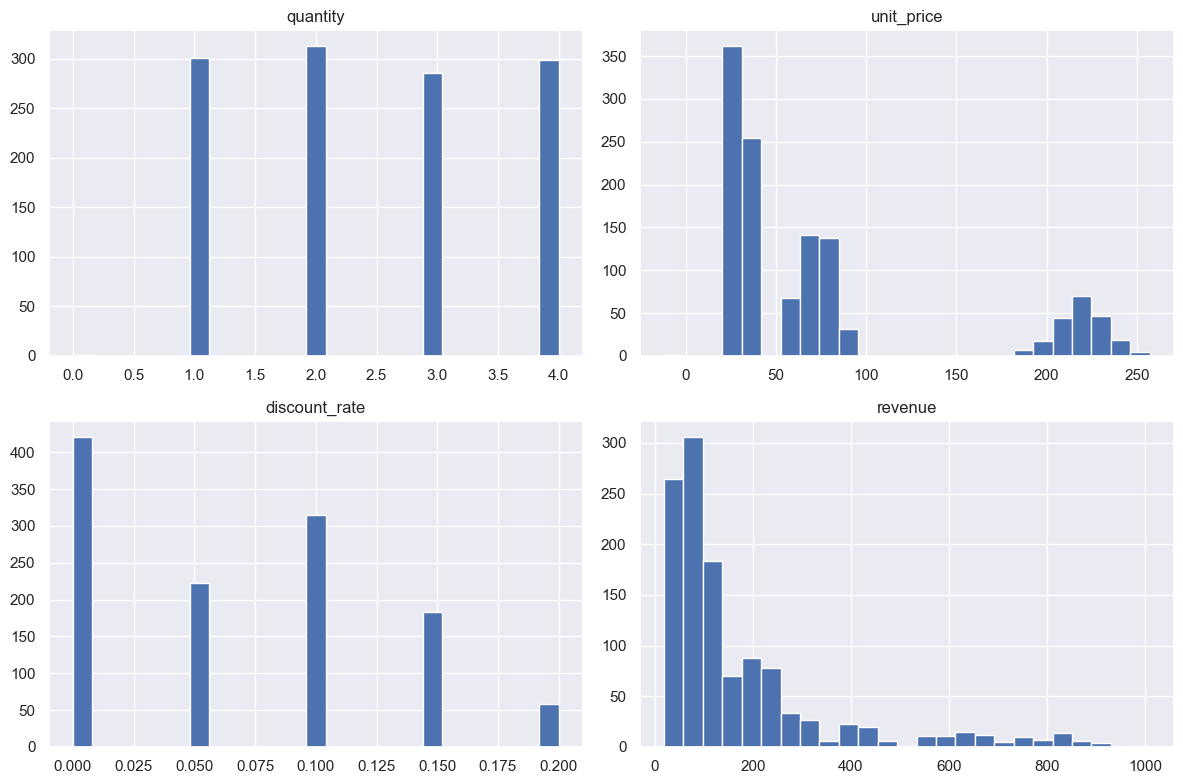

In [4]:
display(describe_numeric(df))
numeric_cols = ["quantity", "unit_price", "discount_rate", "revenue"]
df[numeric_cols].hist(figsize=(12, 8), bins=25)
plt.tight_layout()
plt.show()

## 4. Revenue by category
Compare total revenue and order counts. Aggregate totals and average order revenue answer different questions.

,orders,total_revenue,mean_revenue,median_revenue
product,,,,
Monitor,207,102826.58,496.746763,450.40
Webcam,196,36175.06,184.566633,181.47
Keyboard,181,26735.68,147.710939,133.63
Laptop Stand,213,18092.44,84.941033,86.75
USB Hub,210,14497.57,69.036048,63.47
Mouse,193,11030.32,57.151917,50.69


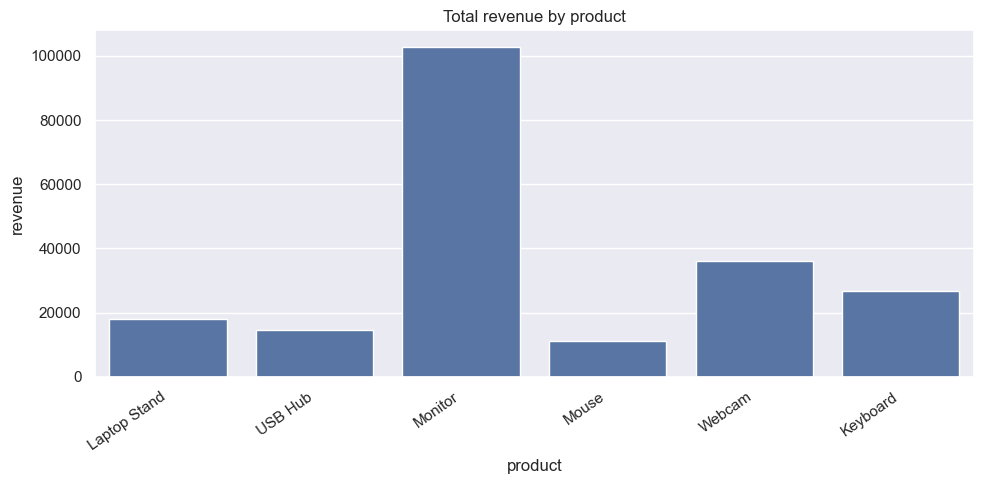

In [5]:
display(df.groupby("product", dropna=False).agg(
    orders=("order_id", "count"),
    total_revenue=("revenue", "sum"),
    mean_revenue=("revenue", "mean"),
    median_revenue=("revenue", "median")
).sort_values("total_revenue", ascending=False))
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="product", y="revenue", estimator="sum", errorbar=None)
plt.xticks(rotation=35, ha="right")
plt.title("Total revenue by product")
plt.tight_layout()
plt.show()

## 5. Correlation analysis
Pearson correlation measures linear association between numeric variables. It does not establish causation and may be distorted by outliers.

,quantity,unit_price,discount_rate,revenue
quantity,1.000000,-0.026418,-0.026562,0.404010
unit_price,-0.026418,1.000000,-0.015423,0.811470
discount_rate,-0.026562,-0.015423,1.000000,-0.069937
revenue,0.404010,0.811470,-0.069937,1.000000


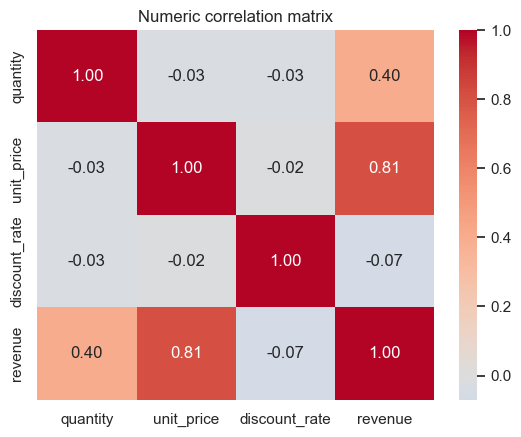

{'x': 'quantity',
 'y': 'revenue',
 'n': 1200,
 'pearson_r': 0.404009926283759,
 'p_value': 2.4963569761054324e-48}

In [6]:
corr = df.select_dtypes(include=np.number).corr(method="pearson")
display(corr)
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Numeric correlation matrix")
plt.show()
display(pearson_test(df, "quantity", "revenue"))

## 6. Outliers and business rules
IQR fences flag unusual values, not necessarily errors. Validate against business rules and source systems before correcting or deleting anything.

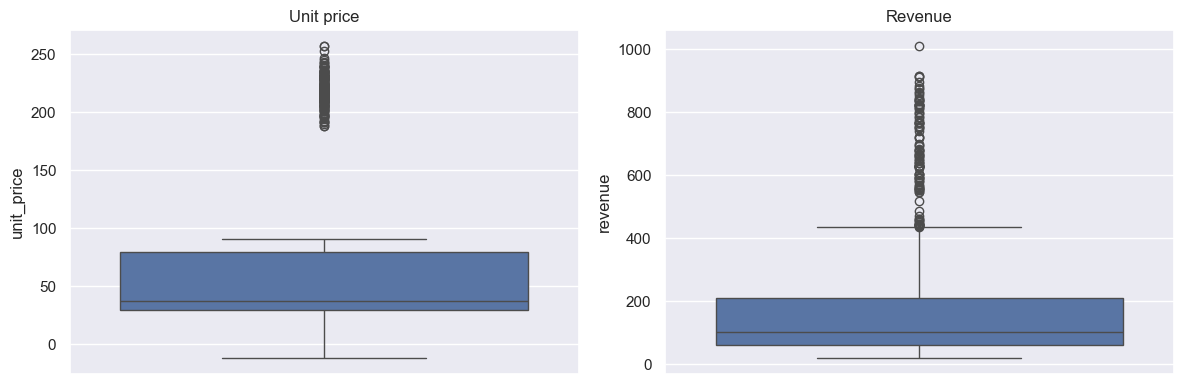

,order_id,order_date,product,quantity,unit_price,discount_rate,region,sales_channel,revenue
17,ORD00018,2025-01-18,Laptop Stand,3,36.79,0.10,NaN,Mobile App,99.33
88,ORD00089,2025-03-30,USB Hub,1,28.57,0.20,NaN,Marketplace,22.86
219,ORD00220,2025-08-08,Webcam,2,79.21,0.10,NaN,Website,142.58
450,ORD00451,2026-03-27,Webcam,0,76.75,0.05,South,Mobile App,72.91
701,ORD00702,2026-12-03,Monitor,3,-12.00,0.10,South,Website,599.62


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, y="unit_price", ax=axes[0])
sns.boxplot(data=df, y="revenue", ax=axes[1])
axes[0].set_title("Unit price")
axes[1].set_title("Revenue")
plt.tight_layout()
plt.show()
# Example candidate review table; retain original data.
display(df[(df["quantity"] <= 0) | (df["unit_price"] <= 0) | df["region"].isna()])

## 7. Automated profiling report
This creates an HTML report in `reports/`. For large datasets, consider `minimal=True` or sampling to reduce runtime and memory use.

In [8]:
report_path = PROJECT_ROOT / "reports/ecommerce_profile.html"
create_profile(df, "E-commerce EDA Profile", report_path)
print("Saved:", report_path)

Saved: E:\Linkific\Day 7\reports\ecommerce_profile.html


C:\Users\niran\AppData\Local\Temp\ipykernel_9656\533929696.py:2: RuntimeWarning: ydata-profiling is not installed in this Python environment; writing a basic HTML summary instead.
  create_profile(df, "E-commerce EDA Profile", report_path)


## Findings template
Write 3–5 evidence-based findings. Include metric, comparison, caveat, and recommended follow-up. Do not claim causation from correlation.